# 1 · Knowledge holds, alignment erodes — and what changes the rate

**Question.** When a vision–language model is continually trained on new text, what happens to what it *knows*
versus how it *behaves* — and does behaviour on **image** inputs erode differently from **text** inputs?

**Runs.** Qwen3.5 with the vision tower frozen, 1M tokens each, in the *gentle regime* (SGD + momentum, LR 1e-4,
pure 16-bit weights): 0.8B on the laptop, 2B on Kaggle (fp16, verified fast kernels). Two kinds of training text:
**code** (codeparrot) and **chat-like** (ultrachat user turns).

**Measures.**
- **Knowledge — ARC:** 300 science questions as text, 100 also rendered as images. *Net lost* = items right at the
  start and wrong later, minus the reverse.
- **Refusal:** for 64 matched harmful/harmless request pairs, the log-odds of starting a refusal rather than a
  compliance at the first response token. The **gap** (harmful minus harmless) is how well refusal discriminates;
  *kept* = gap now ÷ gap at start. Three framings of the same requests: **plain** text, **wrapped** text
  ("The following is a question from a user…"), and the request **rendered as an image** with a matching wrapper.
  Image-vs-text comparisons use *wrapped*, so the framing is matched.

In [1]:
import sys, os; sys.path.insert(0, ".")
import numpy as np, pandas as pd
from kwm import *
setup(); pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
RUNS = {"0.8B · code": load("erosion/D2_erosion_Qwen3.5-0.8B_code_gentle_seed0.json"),
        "0.8B · chat-like": load("erosion/D2_erosion_Qwen3.5-0.8B_chat_gentle_seed0.json"),
        "2B · code": load("erosion/D3_erosion_Qwen3.5-2B_code_gentle.json"),
        "2B · chat-like": load("erosion/D3_erosion_Qwen3.5-2B_chat_gentle.json")}
rows = []
for name, R in RUNS.items():
    r, b = R[-1], R[0]["baseline"]; lw, li = lost(r, "kept_text_wrap"), lost(r, "kept_image_wrap")
    rows.append({"run": name, "tokens": f"{r['tokens']:,}", "ARC items lost (net)": r["arc_net_lost"],
                 "image refusal at start, % of text": round(100 * b["gap_image_wrap"] / b["gap_text_wrap"]),
                 "plain lost %": round(lost(r, "kept_text_plain"), 1), "wrapped lost %": round(lw, 1),
                 "image lost %": round(li, 1), "image ÷ wrapped": round(li / lw, 2),
                 "held-out chat loss ratio": round(r["ppl_ratio"], 3)})
pd.DataFrame(rows).set_index("run")

,tokens,ARC items lost (net),"image refusal at start, % of text",plain lost %,wrapped lost %,image lost %,image ÷ wrapped,held-out chat loss ratio
run,,,,,,,,
0.8B · code,"1,003,520",1,31,0.9,2.5,3.5,1.40,0.988
0.8B · chat-like,"1,003,520",8,31,5.8,14.0,29.9,2.14,0.880
2B · code,"1,003,520",-3,70,3.0,2.3,2.7,1.19,0.972
2B · chat-like,"1,003,520",-3,70,-0.1,7.6,2.4,0.32,0.890


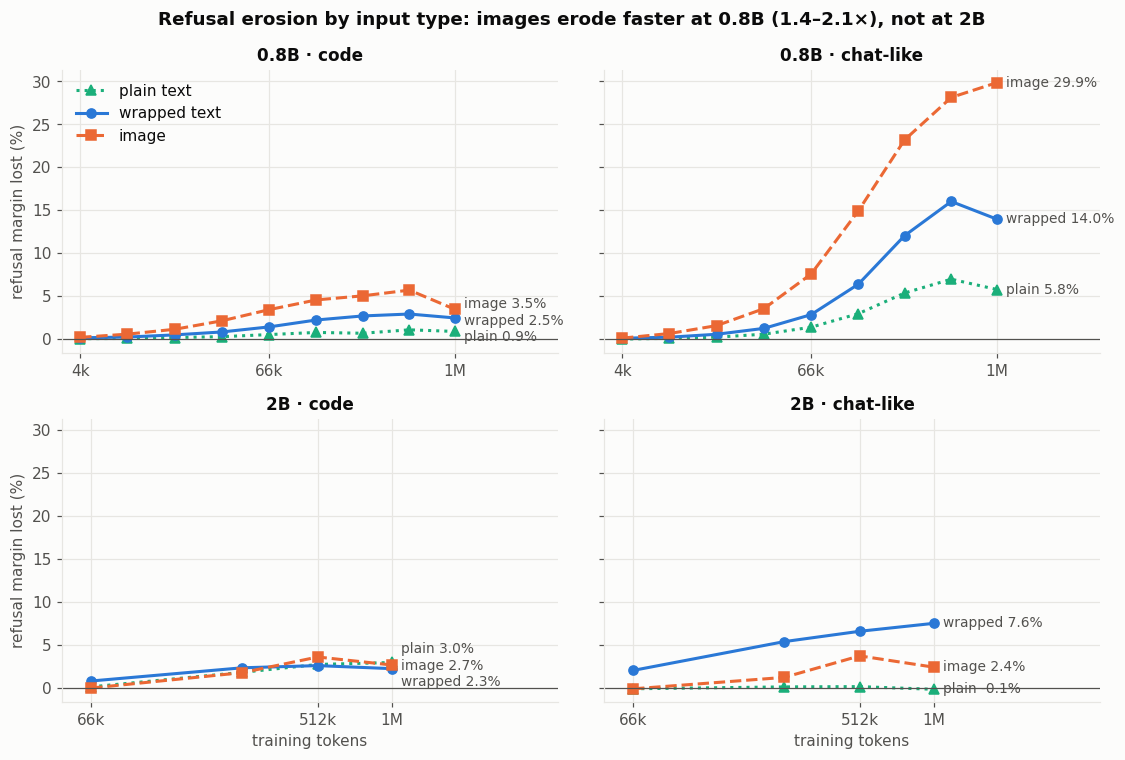

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7), sharey=True)
for ax, (name, R) in zip(axes.flat, RUNS.items()):
    t = [r["tokens"] for r in R]
    ends = []
    for key, lab, col, ls, mk in (("kept_text_plain", "plain text", AQUA, ":", "^"),
                                  ("kept_text_wrap", "wrapped text", BLUE, "-", "o"),
                                  ("kept_image_wrap", "image", ORANGE, "--", "s")):
        y = [lost(r, key) for r in R]
        ax.plot(t, y, color=col, ls=ls, marker=mk, label=lab); ends.append((y[-1], f"{lab.split()[0]} {y[-1]:.1f}%"))
    end_labels(ax, t[-1], ends, gap=1.9)
    ax.axhline(0, color=INK2, lw=0.8); ax.set_title(name)
    tok_axis(ax, [t[0], t[len(t) // 2], t[-1]]); ax.set_xlim(t[0] / 1.3, t[-1] * 4.5)
for ax in axes[:, 0]: ax.set_ylabel("refusal margin lost (%)")
for ax in axes[1, :]: ax.set_xlabel("training tokens")
axes[0, 0].legend(loc="upper left")
fig.suptitle("Refusal erosion by input type: images erode faster at 0.8B (1.4–2.1×), not at 2B", fontweight="bold")
fig.tight_layout(); plt.show()

**Decay laws.** Each channel is fitted with `lost% = a·log2(tokens) + b`. The slope is the erosion rate per doubling of training.

In [3]:
fits = []
for name, R in RUNS.items():
    t = [r["tokens"] for r in R]
    for key, lab in (("kept_text_wrap", "wrapped text"), ("kept_image_wrap", "image")):
        a, _, r2 = decay_fit(t, [lost(r, key) for r in R])
        fits.append({"run": name, "channel": lab, "slope, % per doubling": round(a, 3), "R²": round(r2, 2), "points": len(t)})
pd.DataFrame(fits).set_index(["run", "channel"])

slope, % per doubling    R²  points
run              channel                                          
0.8B · code      wrapped text                  0.387  0.91       9
                 image                         0.649  0.78       9
0.8B · chat-like wrapped text                  2.193  0.86       9
                 image                         4.291  0.92       9
2B · code        wrapped text                  0.403  0.71       4
                 image                         0.808  0.78       4
2B · chat-like   wrapped text                  1.412  0.98       4
                 image                         0.808  0.69       4

**Knowledge over the same training.**

In [4]:
k = []
for name, R in RUNS.items():
    b = R[0]["baseline"]
    k.append({"run": name, "ARC text at start": round(b["arc_text"], 3),
              "ARC text during training": f"{min(r['arc_text'] for r in R):.3f}–{max(r['arc_text'] for r in R):.3f}",
              "ARC image at start": round(b["arc_image"], 2),
              "ARC image during training": f"{min(r['arc_image'] for r in R):.2f}–{max(r['arc_image'] for r in R):.2f}",
              "worst net ARC items lost": max(r["arc_net_lost"] for r in R)})
pd.DataFrame(k).set_index("run")

,ARC text at start,ARC text during training,ARC image at start,ARC image during training,worst net ARC items lost
run,,,,,
0.8B · code,0.860,0.857–0.863,0.78,0.77–0.79,1
0.8B · chat-like,0.860,0.833–0.863,0.78,0.75–0.79,8
2B · code,0.923,0.927–0.933,0.83,0.82–0.83,-1
2B · chat-like,0.923,0.927–0.937,0.83,0.82–0.86,-1


**Second seed (0.8B).** The same runs with a different sample of training text; measurement items unchanged.

In [5]:
rows = []
for data, f0, f1 in (("chat-like", "D2_erosion_Qwen3.5-0.8B_chat_gentle_seed0", "D5_erosion_Qwen3.5-0.8B_chat_gentle_seed1"), ("code", "D2_erosion_Qwen3.5-0.8B_code_gentle_seed0", "D5_erosion_Qwen3.5-0.8B_code_gentle_seed1")):
    for seed, f in ((0, f0), (1, f1)):
        r = load(f"erosion/{f}.json")[-1]; lw, li = lost(r, "kept_text_wrap"), lost(r, "kept_image_wrap")
        rows.append({"data": data, "seed": seed, "wrapped lost %": round(lw, 1), "image lost %": round(li, 1), "image ÷ wrapped": round(li / lw, 2), "ARC net lost": r["arc_net_lost"]})
pd.DataFrame(rows).set_index(["data", "seed"])

wrapped lost %  image lost %  image ÷ wrapped  ARC net lost
data      seed                                                             
chat-like 0               14.0          29.9             2.14             8
          1               14.5          28.7             1.98             8
code      0                2.5           3.5             1.40             1
          1                5.7           4.7             0.84             1

Chat-like replicates closely. Code does not: a different code sample doubled the wrapped-text loss and removed the image effect. The data sample matters even within a data type.

**Why one 2B run is excluded.** The first 2B run probably used *emulated* bf16 on the T4 (see `results/erosion/flagged/`).

In [6]:
flag, good = load("erosion/flagged/D3_erosion_Qwen3.5-2B_code_gentle_BF16-SUSPECT.json")[-1], RUNS["2B · code"][-1]
print("Text erosion matches; image erosion is 1.6x higher in the flagged run, which is what made 2B look no safer than 0.8B.")
pd.DataFrame([{"2B code at 1M tokens": "probable emulated bf16 (flagged)", "wrapped lost %": round(lost(flag, "kept_text_wrap"), 2), "image lost %": round(lost(flag, "kept_image_wrap"), 2)},
              {"2B code at 1M tokens": "fp16 (used)", "wrapped lost %": round(lost(good, "kept_text_wrap"), 2), "image lost %": round(lost(good, "kept_image_wrap"), 2)}]).set_index("2B code at 1M tokens")

Text erosion matches; image erosion is 1.6x higher in the flagged run, which is what made 2B look no safer than 0.8B.


,wrapped lost %,image lost %
2B code at 1M tokens,,
probable emulated bf16 (flagged),2.29,4.36
fp16 (used),2.28,2.70


## What this shows
1. **Knowledge holds.** The worst run loses 8 of 300 ARC items net (0.8B, chat-like); the other three lose at
   most 1, while refusal erodes in every run.
2. **The kind of data sets the rate.** At 0.8B, chat-like text erodes refusal far more than code on every framing
   (wrapped 14.0% vs 2.5%, 5.6×; image 29.9% vs 3.5%). At 2B it still erodes wrapped requests about 3× more
   (7.6% vs 2.3%), but not plain requests (−0.1% vs 3.0%) or images (2.4% vs 2.7%).
3. **Image-input refusal erodes faster at 0.8B (first-token measure, chat-like data), not at 2B.** At 0.8B images lose 1.4× (code) and 2.1× (chat-like)
   the share wrapped text loses; at 2B, in the same number format, 1.2× (code) and 0.3× (chat-like). The 2B model
   also starts with much stronger image refusal (70% of text strength vs 31%).
4. **Scale protects on chat-like data:** 2B loses 7.6% vs 14.0% (wrapped) and 2.4% vs 29.9% (image). On code the
   two sizes erode about the same (wrapped 2.3% vs 2.5%).
5. **Framing matters at 2B:** on chat-like data, wrapped requests lost 7.6% while plain requests lost nothing.

## Caveats
- *Gentle regime:* 1M tokens, SGD, pure 16-bit weights — far weaker than real continual pre-training, and small
  updates round away (THESIS_LOG entries 17 and 20). Treat rates as lower bounds; notebook 3 covers the realistic regime.
- Refusal is read from the first response token. For text it matches generated refusals closely (notebook 4); for
  images it does not track them over training, so image erosion here is erosion of the *inclination* to refuse.
- Images are rendered text here; notebook 5 has natural photos.